# EUS DaRT seed detection

Hi Mina and Liam,

This notebook loads the dataset, displays the seed annotations, and provides a small YOLO training example.
The images are grouped into **six segments**. Each segment has an `images` folder and a matching `labels` folder.

- **Task:** detect seeds with rotated bounding boxes (YOLO OBB).
- **Class:** `0 = seed`.
- **Start here:** run sections 1–4 to inspect the data. Section 5 makes a video; section 6b runs a short training example.

Keep each segment together when choosing training and evaluation data. If the same physical seed appears in more
than one segment, keep those segments together too.


## 1. Install packages
Viewing works on CPU. The YOLO package is installed only when you reach the training example.


In [ ]:
!pip -q install gdown==5.2.0 Pillow pandas PyYAML ipywidgets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.3 MB/s eta 0:00:00


## 2. Load the dataset
Run this cell to download and extract the images and labels. Downloads are reused within the current session.
For local work, [download the ZIP](https://drive.google.com/file/d/1w2D7QvPrSHMnZGNcWMO08RK2i6fpS9Je/view?usp=sharing).


In [ ]:
from pathlib import Path
import shlex, zipfile, subprocess, tempfile, shutil
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw
from IPython.display import display, Video

DRIVE_ID = "1w2D7QvPrSHMnZGNcWMO08RK2i6fpS9Je"
WORK = Path("/content/eus_seed_detection")
WORK.mkdir(parents=True, exist_ok=True)
ZIP_PATH = WORK / "dataset.zip"
DATA_ROOT = WORK / "dataset"

if not zipfile.is_zipfile(ZIP_PATH):
    zip_arg = shlex.quote(str(ZIP_PATH))
    !gdown {DRIVE_ID} -O {zip_arg}
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("The dataset download failed. Check access to the Drive file.")
if not (DATA_ROOT / ".extracted").exists():
    DATA_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        for item in archive.infolist():
            if not (DATA_ROOT / item.filename).resolve().is_relative_to(DATA_ROOT.resolve()):
                raise ValueError("Invalid archive path.")
        archive.extractall(DATA_ROOT)
    (DATA_ROOT / ".extracted").touch()
print("Dataset folder:", DATA_ROOT)


Downloading...
From (original): https://drive.google.com/uc?id=1w2D7QvPrSHMnZGNcWMO08RK2i6fpS9Je
From (redirected): https://drive.google.com/uc?id=1w2D7QvPrSHMnZGNcWMO08RK2i6fpS9Je&confirm=t&uuid=2534a231-f3dd-4afa-aa83-d75f61526979
To: /content/eus_seed_detection/dataset.zip
100% 4.36G/4.36G [01:14<00:00, 58.9MB/s]
Dataset folder: /content/eus_seed_detection/dataset


## 3. Dataset overview
A label file contains one row per seed: `class x1 y1 x2 y2 x3 y3 x4 y4`.
The four corners are normalized to the image width and height. An empty label file has no annotated seeds.
Review these images before using them as background examples.


In [ ]:
def load_boxes(label_path):
    text = Path(label_path).read_text().strip()
    if not text:
        return np.empty((0, 9), dtype=float)
    boxes = np.array([list(map(float, line.split())) for line in text.splitlines() if line.strip()])
    if boxes.ndim != 2 or boxes.shape[1] != 9:
        raise ValueError(f"Expected YOLO OBB labels: {label_path}")
    if not np.isfinite(boxes).all() or not (boxes[:, 0] == 0).all() or not ((boxes[:, 1:] >= 0) & (boxes[:, 1:] <= 1)).all():
        raise ValueError(f"Invalid class or coordinates: {label_path}")
    return boxes

records = []
for segment_dir in sorted(DATA_ROOT.glob("segment[1-6]")):
    image_paths = sorted(p for p in (segment_dir / "images").iterdir()
                         if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"})
    for index, image_path in enumerate(image_paths):
        label_path = segment_dir / "labels" / (image_path.stem + ".txt")
        if not label_path.is_file():
            raise FileNotFoundError(f"Missing label: {label_path}")
        records.append({"segment": segment_dir.name, "index": index,
                        "image": image_path, "label": label_path,
                        "n_boxes": len(load_boxes(label_path))})
frames = pd.DataFrame(records)
if frames.empty:
    raise ValueError("No images found. Expected segment1/images through segment6/images.")
summary = frames.groupby("segment").agg(
    images=("index", "size"), annotated_images=("n_boxes", lambda x: (x > 0).sum()),
    seed_boxes=("n_boxes", "sum"))
summary["empty_labels"] = summary.images - summary.annotated_images
display(summary)


,images,annotated_images,seed_boxes,empty_labels
segment,,,,
segment1,225,138,138,87
segment2,254,242,242,12
segment3,456,407,407,49
segment4,524,516,516,8
segment5,500,439,840,61
segment6,749,370,372,379


## 4. View images and boxes
Choose a segment and an image index, starting at **0** within that segment. Green outlines show the annotations.
Set `boxes=False` to view the ultrasound image alone.


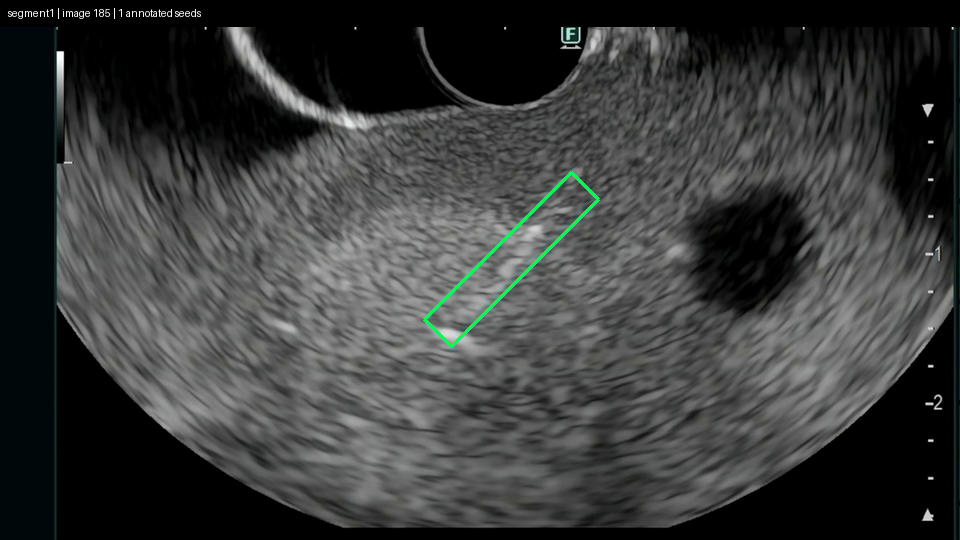

In [ ]:
def segment_frames(segment):
    selected = frames.loc[frames.segment == segment].sort_values("index").reset_index(drop=True)
    if selected.empty:
        raise ValueError(f"Unknown or empty segment: {segment}")
    return selected

def draw_frame(row, boxes=True, max_width=960):
    with Image.open(row.image) as source:
        image = source.convert("RGB")
    width = min(max_width, image.width) // 2 * 2
    height = max(2, round(image.height * width / image.width) // 2 * 2)
    image = image.resize((width, height), Image.Resampling.LANCZOS)
    draw = ImageDraw.Draw(image)
    if boxes:
        for label in load_boxes(row.label):
            points = label[1:].reshape(4, 2) * [width, height]
            polygon = [tuple(point) for point in points]
            draw.line(polygon + [polygon[0]], fill=(0, 255, 80), width=3)
    draw.rectangle((0, 0, width, 26), fill="black")
    draw.text((8, 7), f"{row.segment} | image {int(row['index'])} | {int(row.n_boxes)} annotated seeds", fill="white")
    return image

def show_frame(segment="segment1", index=0, boxes=True):
    selected = segment_frames(segment)
    if not 0 <= index < len(selected):
        raise ValueError(f"Choose an index from 0 to {len(selected)-1}.")
    display(draw_frame(selected.iloc[index], boxes=boxes))

show_frame("segment1", index=185)


### Browse interactively
Use the slider to move through a segment. Uncheck the box to hide the annotations.


In [ ]:
import ipywidgets as widgets
segment_picker = widgets.Dropdown(options=sorted(frames.segment.unique()), description="Segment:")
image_slider = widgets.IntSlider(value=0, min=0, max=len(segment_frames(segment_picker.value))-1,
                                description="Image:", continuous_update=False)
box_toggle = widgets.Checkbox(value=True, description="Show annotations")
viewer = widgets.Output()

def refresh_view(change=None):
    with viewer:
        viewer.clear_output(wait=True)
        show_frame(segment_picker.value, image_slider.value, box_toggle.value)

def change_segment(change):
    image_slider.value = 0
    image_slider.max = len(segment_frames(segment_picker.value)) - 1
    refresh_view()

segment_picker.observe(change_segment, names="value")
image_slider.observe(refresh_view, names="value")
box_toggle.observe(refresh_view, names="value")
display(widgets.VBox([segment_picker, image_slider, box_toggle, viewer]))
refresh_view()


## 5. Watch an annotated video
The example below renders **100 images from segment1** at 10 images per second.
Change `segment`, `start`, or `stop` to view another selection. Set `stop=None` for a whole segment.
Playback speed affects only the preview.


In [ ]:
def render_video(segment="segment1", start=0, stop=100, fps=10, max_width=960):
    if fps <= 0 or start < 0:
        raise ValueError("Use a positive fps and a nonnegative start index.")
    if not shutil.which("ffmpeg"):
        raise RuntimeError("ffmpeg is required; it is available in Colab.")
    selected = segment_frames(segment).iloc[start:stop]
    if selected.empty:
        raise ValueError("No images selected.")
    size = draw_frame(selected.iloc[0], max_width=max_width).size
    output = WORK / f"{segment}_preview.mp4"
    with (WORK / "video.log").open("wb") as log:
        process = subprocess.Popen([
            "ffmpeg", "-hide_banner", "-loglevel", "error", "-y",
            "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{size[0]}x{size[1]}",
            "-r", str(fps), "-i", "-", "-an", "-c:v", "libx264", "-preset", "fast",
            "-crf", "23", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(output)
        ], stdin=subprocess.PIPE, stderr=log)
        try:
            for _, row in selected.iterrows():
                image = draw_frame(row, max_width=max_width)
                if image.size != size:
                    raise ValueError("Selected images have different dimensions.")
                process.stdin.write(image.tobytes())
            process.stdin.close()
            if process.wait() != 0:
                raise RuntimeError((WORK / "video.log").read_text())
        except BaseException:
            process.kill(); process.wait()
            raise
    return output

video_path = render_video("segment1", start=0, stop=100, fps=10)
display(Video(str(video_path), embed=True, width=960))


## 6. Load images and labels in Python
`frames` is the dataset index. Filter it by segment, then load an image as an RGB array and its boxes as pixel coordinates.
Apply any crop, rotation, or resize to the image and its boxes together. YOLO handles this during training.


In [ ]:
selected = segment_frames("segment3")
row = selected.iloc[0]
with Image.open(row.image) as image:
    image_rgb = np.asarray(image.convert("RGB"))
labels = load_boxes(row.label)                     # shape: (number of seeds, 9)
height, width = image_rgb.shape[:2]
corners_px = labels[:, 1:].reshape(-1, 4, 2) * [width, height]
print("Image shape:", image_rgb.shape)
print("Seed boxes:", corners_px.shape)
print("First box corners:", corners_px[:1])


Image shape: (1080, 1920, 3)
Seed boxes: (1, 4, 2)
First box corners: [[[1322.6112   335.63376]
  [1379.43744  350.8596 ]
  [1268.73792  763.99632]
  [1211.91168  748.7694 ]]]


## 6b. Quick YOLO training example
This runs **one epoch on 8 annotated images**, with 4 images from another segment for validation, using a nano OBB model.
It checks that the training code runs; the resulting predictions and metrics are not a performance estimate.
The first run also installs the package and downloads the model weights.


In [ ]:
%pip -q install ultralytics
from ultralytics import YOLO
import torch

def write_yolo_data(train_rows, val_rows, test_rows=None):
    sets = {"train": train_rows, "val": val_rows}
    if test_rows is not None:
        sets["test"] = test_rows
    used_segments = set()
    config_dir = Path(tempfile.mkdtemp(prefix="yolo_", dir=WORK))
    config = {"path": str(config_dir), "names": {0: "seed"}}
    for role, rows in sets.items():
        groups = set(rows.segment)
        if rows.empty or used_segments.intersection(groups):
            raise ValueError("Each split needs images from separate segments.")
        used_segments.update(groups)
        (config_dir / f"{role}.txt").write_text("".join(str(p.resolve()) + "\n" for p in rows.image))
        config[role] = f"{role}.txt"
    config_path = config_dir / "data.yaml"
    config_path.write_text(yaml.safe_dump(config))
    return config_path

example_train = frames.query("segment == 'segment1' and n_boxes > 0").head(8)
example_val = frames.query("segment == 'segment2' and n_boxes > 0").head(4)
assert len(example_train) == 8 and len(example_val) == 4, "Not enough annotated images."
example_yaml = write_yolo_data(example_train, example_val)
device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO("yolov8n-obb.pt")
model.train(data=str(example_yaml), epochs=1, imgsz=320, batch=4, workers=0,
            device=device, amp=False, mosaic=0, close_mosaic=0, plots=False,
            project=str(WORK / "runs"), name="quick_example", seed=42)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 694.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 7.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=Fa

ultralytics.utils.metrics.OBBMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f7b0f5b390>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

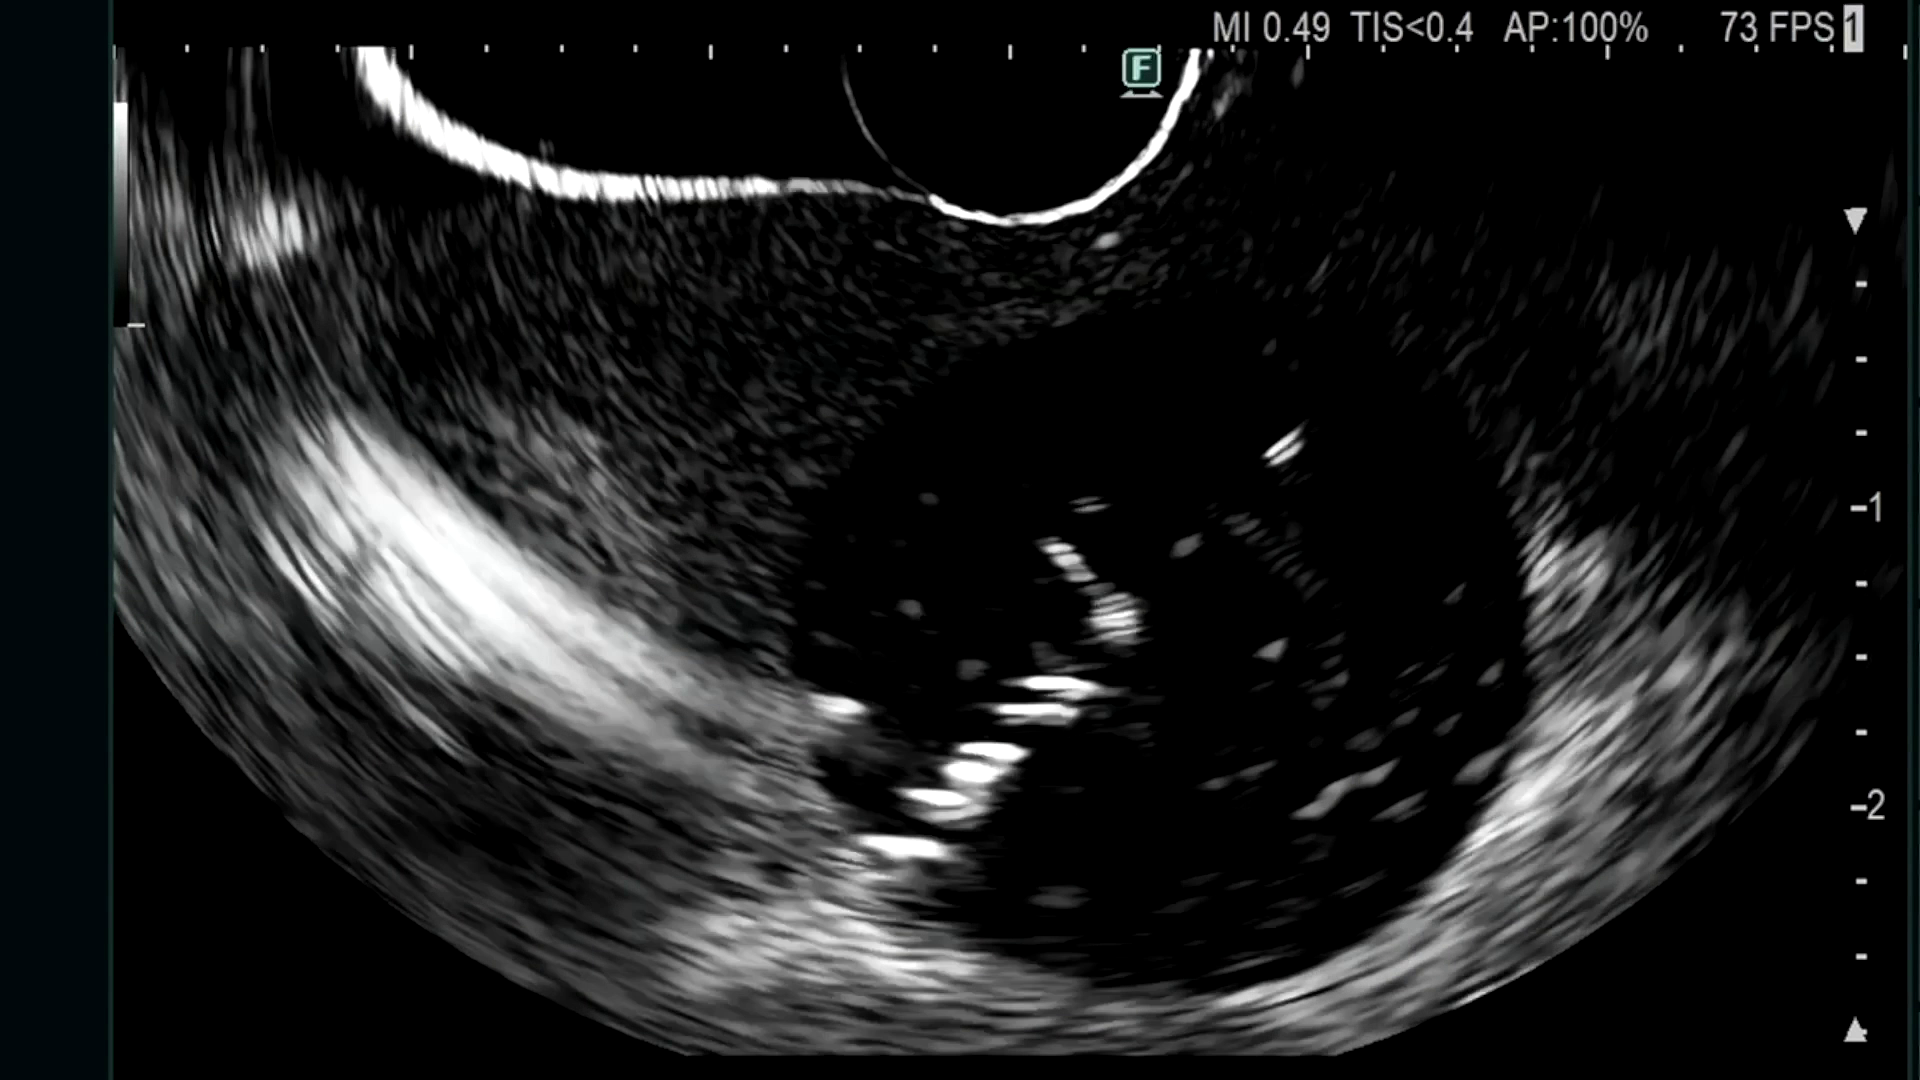

In [ ]:
# Display a prediction from the example model.
result = model.predict(str(example_val.iloc[0].image), imgsz=320, device=device, verbose=False)[0]
display(Image.fromarray(result.plot()[..., ::-1]))


## 7. Set up a full training run
Choose whole segments for each split, then set `RUN_TRAINING=True`. The lists are left empty so we can agree on
the evaluation design first. Keep repeated physical seeds in the same split, even if they appear in different segments.
Use validation data for model selection and reserve test data for final evaluation.

The helper writes image lists and `data.yaml` without moving files. The full run includes images with empty labels;
review their annotations first. `imgsz=1024`, `batch=4`, and `epochs=100` are editable starting values.


In [ ]:
RUN_TRAINING = False
TRAIN_SEGMENTS = []
VAL_SEGMENTS = []
TEST_SEGMENTS = []  # optional

if RUN_TRAINING:
    known = set(frames.segment)
    requested = set(TRAIN_SEGMENTS + VAL_SEGMENTS + TEST_SEGMENTS)
    if not requested.issubset(known):
        raise ValueError("Unknown segment name.")
    train_rows = frames[frames.segment.isin(TRAIN_SEGMENTS)]
    val_rows = frames[frames.segment.isin(VAL_SEGMENTS)]
    test_rows = frames[frames.segment.isin(TEST_SEGMENTS)] if TEST_SEGMENTS else None
    training_yaml = write_yolo_data(train_rows, val_rows, test_rows)
    model = YOLO("yolov8n-obb.pt")  # fresh pretrained model for this run
    results = model.train(data=str(training_yaml), epochs=100, imgsz=1024, batch=4,
                          device=device, workers=2, seed=42,
                          project=str(WORK / "runs"), name="eus_obb")
    print("Best weights:", model.trainer.best)


Training outputs are saved under `/content/eus_seed_detection/runs/`.
Download `weights/best.pt` and `results.csv` from the chosen run before ending the Colab session.
For later inference, load `YOLO("path/to/best.pt")` and call `.predict(...)` on an image or video.
